In [2]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')
from path_setup import setup_project_path
setup_project_path()

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp, softmax
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.decoding.SessionAggregator import SessionAggregator
from src.decoding.Decoders import (
    FactoredMLE,
    TrialDecoder,
    AveragedDecoder
)

%load_ext autoreload
%autoreload 2

figure_dir = r"G:\My Drive\Conferences\CNLM 26\Poster\figure-6"

In [3]:
MOUSE                 = 'SAM041'
EXPERIMENT            = 'tiling_120um'
RANDOM_STATE          = 42
np.random.seed(RANDOM_STATE)

SAM040_agg = SessionAggregator(
    mouse_name='SAM040',
    experiment_name=EXPERIMENT
)

SAM041_agg = SessionAggregator(
    mouse_name='SAM041',
    experiment_name=EXPERIMENT
)

SAM043_agg = SessionAggregator(
    mouse_name='SAM043',
    experiment_name=EXPERIMENT
)

agg = [SAM040_agg, SAM041_agg, SAM043_agg]

Decoder = TrialDecoder()

[ok] Loaded aggregated traces from cache
[ok] Loaded aggregated traces from cache
[ok] Loaded aggregated traces from cache


[ok] Loaded aggregated traces from cache


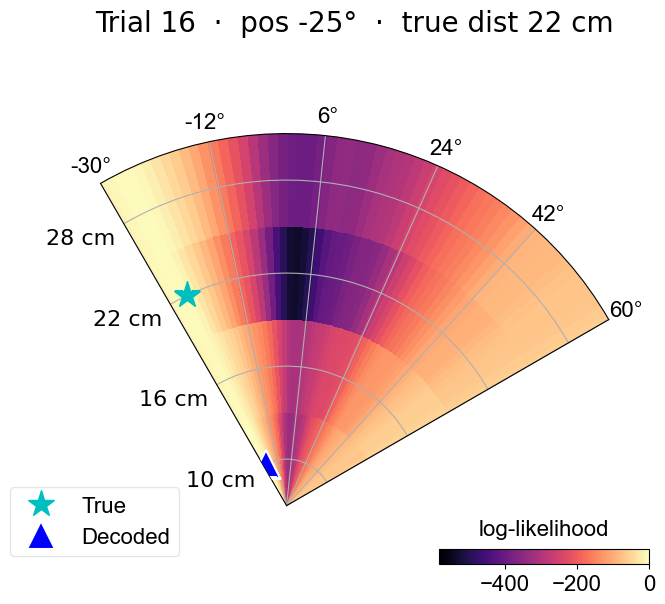

In [20]:
# Get data the same way the CV function does
agg = SessionAggregator(
    mouse_name='SAM041',
    experiment_name=EXPERIMENT
)

X, y_distance = agg.get_decoder_data(monocular=0, area=None, session=3)  # adjust monocular/area as needed
distance_levels = agg.distances   # (n_distances,)
deg_axis        = agg.angle_axis  # (n_angles,)

fig = Decoder.plot_trial_frames(X, trial_id=16,
                                angle_indices=3,
                                y_distance=y_distance,
                                distance_levels=distance_levels,
                                deg_axis=deg_axis)
import os
figure_name = os.path.join(figure_dir, '6A.svg')
plt.rcParams['svg.fonttype'] = 'none'
fig.savefig(figure_name, format='svg')

In [21]:
print(np.shape(X))

(741, 59, 48)


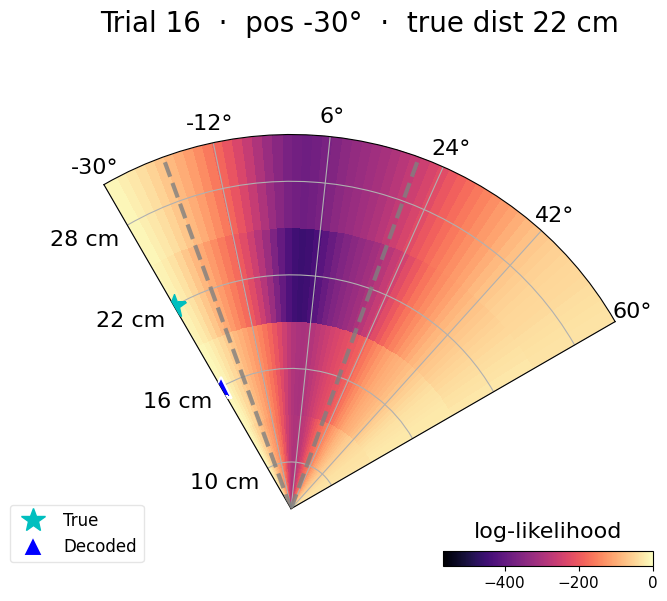

In [269]:
# Or save:
anim = Decoder.animate_trial(X, trial_id=16, y_distance=y_distance,
                                distance_levels=distance_levels, deg_axis=deg_axis,
                                interval=80)

import os
video_dir = os.path.join(figure_dir, 'trial_sweep.mp4')                                
anim.save(video_dir.replace('.mp4', '.gif'), writer='pillow', fps=len(deg_axis)//12, dpi=150)

# Decoder model

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_108712\3573930197.py:46: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(angle_axis, mu_avg[c], '-',


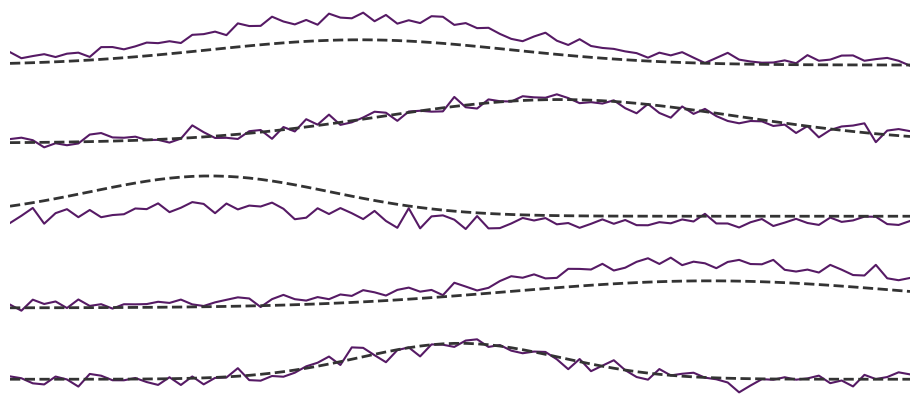

In [232]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
angle_axis = np.linspace(-30, 60, 80)
distances  = np.array([10, 16, 22, 28])
noise_std  = 0.5
base_fr    = 1.0
TRUE_DIST_IDX = 0   # nearest distance — maximizes contrast

dist_colors = ['#440154', '#31688e', '#35b779', '#FFA500']

def gauss(x, mu, sigma, amp):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + base_fr

# gains chosen so the distance signal is clearly visible
cells = [
    dict(pref=  5, sigma=15, amp=4.0, gain=[1.8, 1.2, 0.7, 0.4]),  # fires HIGH at near
    dict(pref= 25, sigma=18, amp=4.0, gain=[1.0, 1.0, 1.0, 1.0]),  # invariant → same as avg
    dict(pref=-10, sigma=12, amp=4.0, gain=[0.4, 0.7, 1.2, 1.8]),  # fires LOW at near
    dict(pref= 40, sigma=20, amp=4.0, gain=[1.5, 1.1, 0.8, 0.5]),  # fires HIGH at near
    dict(pref= 15, sigma=10, amp=4.0, gain=[1.0, 1.0, 1.0, 1.0]),  # invariant → same as avg
]

# averaged response: mean across all distances (mu_angle)
mu_avg = np.array([
    np.mean([gauss(angle_axis, p['pref'], p['sigma'], p['amp']) * g
             for g in p['gain']], axis=0)
    for p in cells
])

# current trial at TRUE_DIST_IDX (above/below/same avg depending on gain)
mu_test = np.array([
    gauss(angle_axis, p['pref'], p['sigma'], p['amp']) * p['gain'][TRUE_DIST_IDX]
    for p in cells
])
test_trial = mu_test + np.random.randn(5, 80) * noise_std

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(5, 1, figsize=(10, 5), sharex=True)
test_color = dist_colors[TRUE_DIST_IDX]

for c, ax in enumerate(axes):
    ax.plot(angle_axis, test_trial[c], '-',
            color=test_color, linewidth=1.5, alpha=0.9)
    ax.plot(angle_axis, mu_avg[c], '-',
            color='#333333', linewidth=2.0, linestyle='--')
    ax.set_xlim(angle_axis[0], angle_axis[-1])
    ax.axis('off')

plt.subplots_adjust(hspace=0.4, left=0.05, right=0.95)
plt.show()


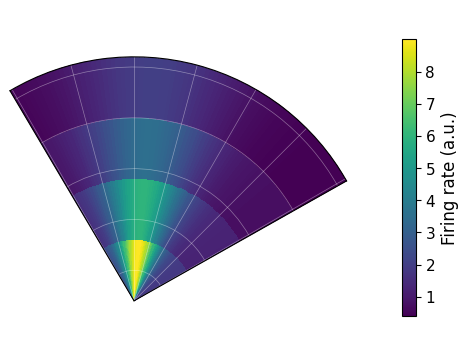

In [237]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
angle_axis = np.linspace(-30, 60, 80)   # dense angles for smooth look
distances  = np.array([10, 16, 22, 28])

def gauss(x, mu, sigma, amp):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + 1.0

cell = dict(pref=5, sigma=15, amp=4.0, gain=[1.8, 1.2, 0.7, 0.4])

tuning   = gauss(angle_axis, cell['pref'], cell['sigma'], cell['amp'])
template = np.outer(tuning, cell['gain'])

dtheta = np.diff(angle_axis).mean()
theta_edges = np.radians(np.append(angle_axis - dtheta/2, angle_axis[-1] + dtheta/2))

dr = np.diff(distances).mean()
r_edges = np.append(distances - dr/2, distances[-1] + dr/2)

fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={'projection': 'polar'})
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)

mesh = ax.pcolormesh(theta_edges, r_edges, template.T,
                     shading='flat', cmap='viridis')

ax.set_thetalim(theta_edges[0], theta_edges[-1])
ax.set_rlim(r_edges[0], r_edges[-1])
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.grid(color='white', linewidth=0.5, alpha=0.4)

plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.12, label='Firing rate (a.u.)')
plt.tight_layout()
plt.show()

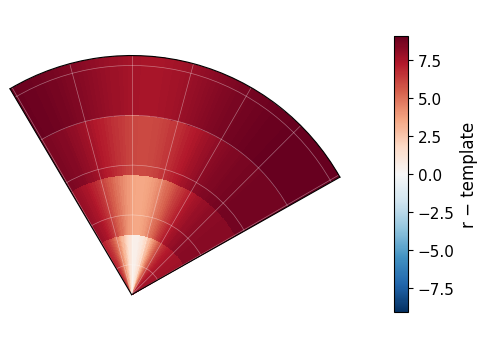

In [238]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
angle_axis = np.linspace(-30, 60, 80)
distances  = np.array([10, 16, 22, 28])

def gauss(x, mu, sigma, amp):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + 1.0

cell = dict(pref=5, sigma=15, amp=4.0, gain=[1.8, 1.2, 0.7, 0.4])

tuning   = gauss(angle_axis, cell['pref'], cell['sigma'], cell['amp'])
template = np.outer(tuning, cell['gain'])   # (n_angles, n_distances)

# single timepoint: true angle ≈ pref, true distance = nearest (idx 0)
TRUE_ANGLE_IDX = np.argmin(np.abs(angle_axis - cell['pref']))
TRUE_DIST_IDX  = 0
r_c = template[TRUE_ANGLE_IDX, TRUE_DIST_IDX] + np.random.randn() * 0.3

# residual map: r - template
residual = r_c - template   # (n_angles, n_distances)

# edges
dtheta = np.diff(angle_axis).mean()
theta_edges = np.radians(np.append(angle_axis - dtheta/2, angle_axis[-1] + dtheta/2))
dr = np.diff(distances).mean()
r_edges = np.append(distances - dr/2, distances[-1] + dr/2)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={'projection': 'polar'})
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)

vmax = np.abs(residual).max()
mesh = ax.pcolormesh(theta_edges, r_edges, residual.T,
                     shading='flat', cmap='RdBu_r',
                     vmin=-vmax, vmax=vmax)

ax.set_thetalim(theta_edges[0], theta_edges[-1])
ax.set_rlim(r_edges[0], r_edges[-1])
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.grid(color='white', linewidth=0.5, alpha=0.4)

plt.colorbar(mesh, ax=ax, shrink=0.6, pad=0.12, label='r − template')
plt.tight_layout()
plt.show()


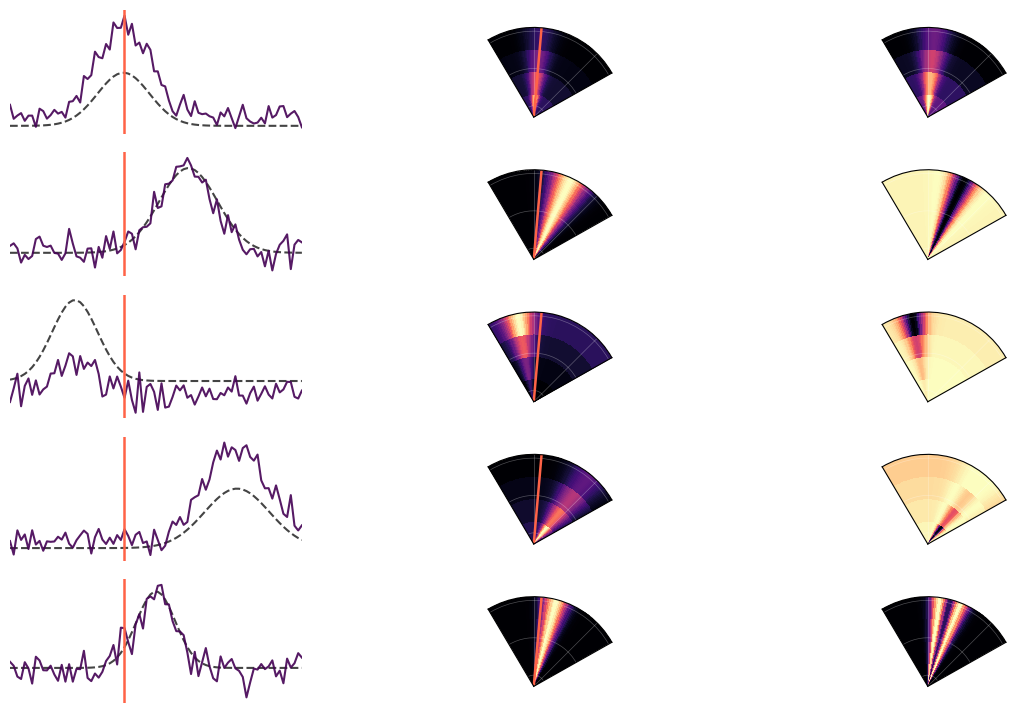

In [244]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(7)
angle_axis    = np.linspace(-30, 60, 80)
distances     = np.array([10, 16, 22, 28])
noise_std     = 0.5
TRUE_DIST_IDX = 0
CHOSEN_ANGLE  = 5.0
chosen_idx    = np.argmin(np.abs(angle_axis - CHOSEN_ANGLE))

dist_colors = ['#440154', '#31688e', '#35b779', '#FFA500']
test_color  = dist_colors[TRUE_DIST_IDX]

def gauss(x, mu, sigma, amp):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + 1.0

cells = [
    dict(pref=  5, sigma=8,  amp=4.0, gain=[1.8, 1.2, 0.7, 0.4]),
    dict(pref= 25, sigma=9,  amp=4.0, gain=[1.0, 1.0, 1.0, 1.0]),
    dict(pref=-10, sigma=7,  amp=4.0, gain=[0.4, 0.7, 1.2, 1.8]),
    dict(pref= 40, sigma=10, amp=4.0, gain=[1.5, 1.1, 0.8, 0.5]),
    dict(pref= 15, sigma=6,  amp=4.0, gain=[1.0, 1.0, 1.0, 1.0]),
]


mu_avg, traces, templates = [], [], []
for p in cells:
    tuning = gauss(angle_axis, p['pref'], p['sigma'], p['amp'])
    mu_avg.append(np.mean([tuning * g for g in p['gain']], axis=0))
    traces.append(tuning * p['gain'][TRUE_DIST_IDX] + np.random.randn(80) * noise_std)
    templates.append(np.outer(tuning, p['gain']))

dtheta       = np.diff(angle_axis).mean()
theta_edges  = np.radians(np.append(angle_axis - dtheta/2, angle_axis[-1] + dtheta/2))
dr           = np.diff(distances).mean()
r_edges      = np.append(distances - dr/2, distances[-1] + dr/2)
chosen_theta = np.radians(CHOSEN_ANGLE)

fig = plt.figure(figsize=(12, 9))
gs  = gridspec.GridSpec(5, 3, figure=fig, hspace=0.15, wspace=0.35,
                        left=0.05, right=0.95)

def polar_ax(fig, gs_cell):
    ax = fig.add_subplot(gs_cell, projection='polar')
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ax.set_thetalim(theta_edges[0], theta_edges[-1])
    ax.set_rlim(r_edges[0], r_edges[-1])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.grid(color='white', linewidth=0.5, alpha=0.3)
    return ax

for c in range(5):
    ax_l = fig.add_subplot(gs[c, 0])
    ax_l.plot(angle_axis, mu_avg[c], '--', color='#444444', linewidth=1.5)
    ax_l.plot(angle_axis, traces[c],  '-', color=test_color, linewidth=1.5, alpha=0.9)
    ax_l.axvline(CHOSEN_ANGLE, color='tomato', linewidth=1.8)
    ax_l.set_xlim(angle_axis[0], angle_axis[-1])
    ax_l.axis('off')

    ax_m = polar_ax(fig, gs[c, 1])
    ax_m.pcolormesh(theta_edges, r_edges, templates[c].T,
                    shading='flat', cmap='magma')
    ax_m.plot([chosen_theta, chosen_theta], [r_edges[0], r_edges[-1]],
              color='tomato', linewidth=1.8)

    r_c      = traces[c][chosen_idx]
    sq_resid = (r_c - templates[c]) ** 2

    ax_r = polar_ax(fig, gs[c, 2])
    ax_r.pcolormesh(theta_edges, r_edges, -sq_resid.T,
                    shading='flat', cmap='magma')

plt.show()


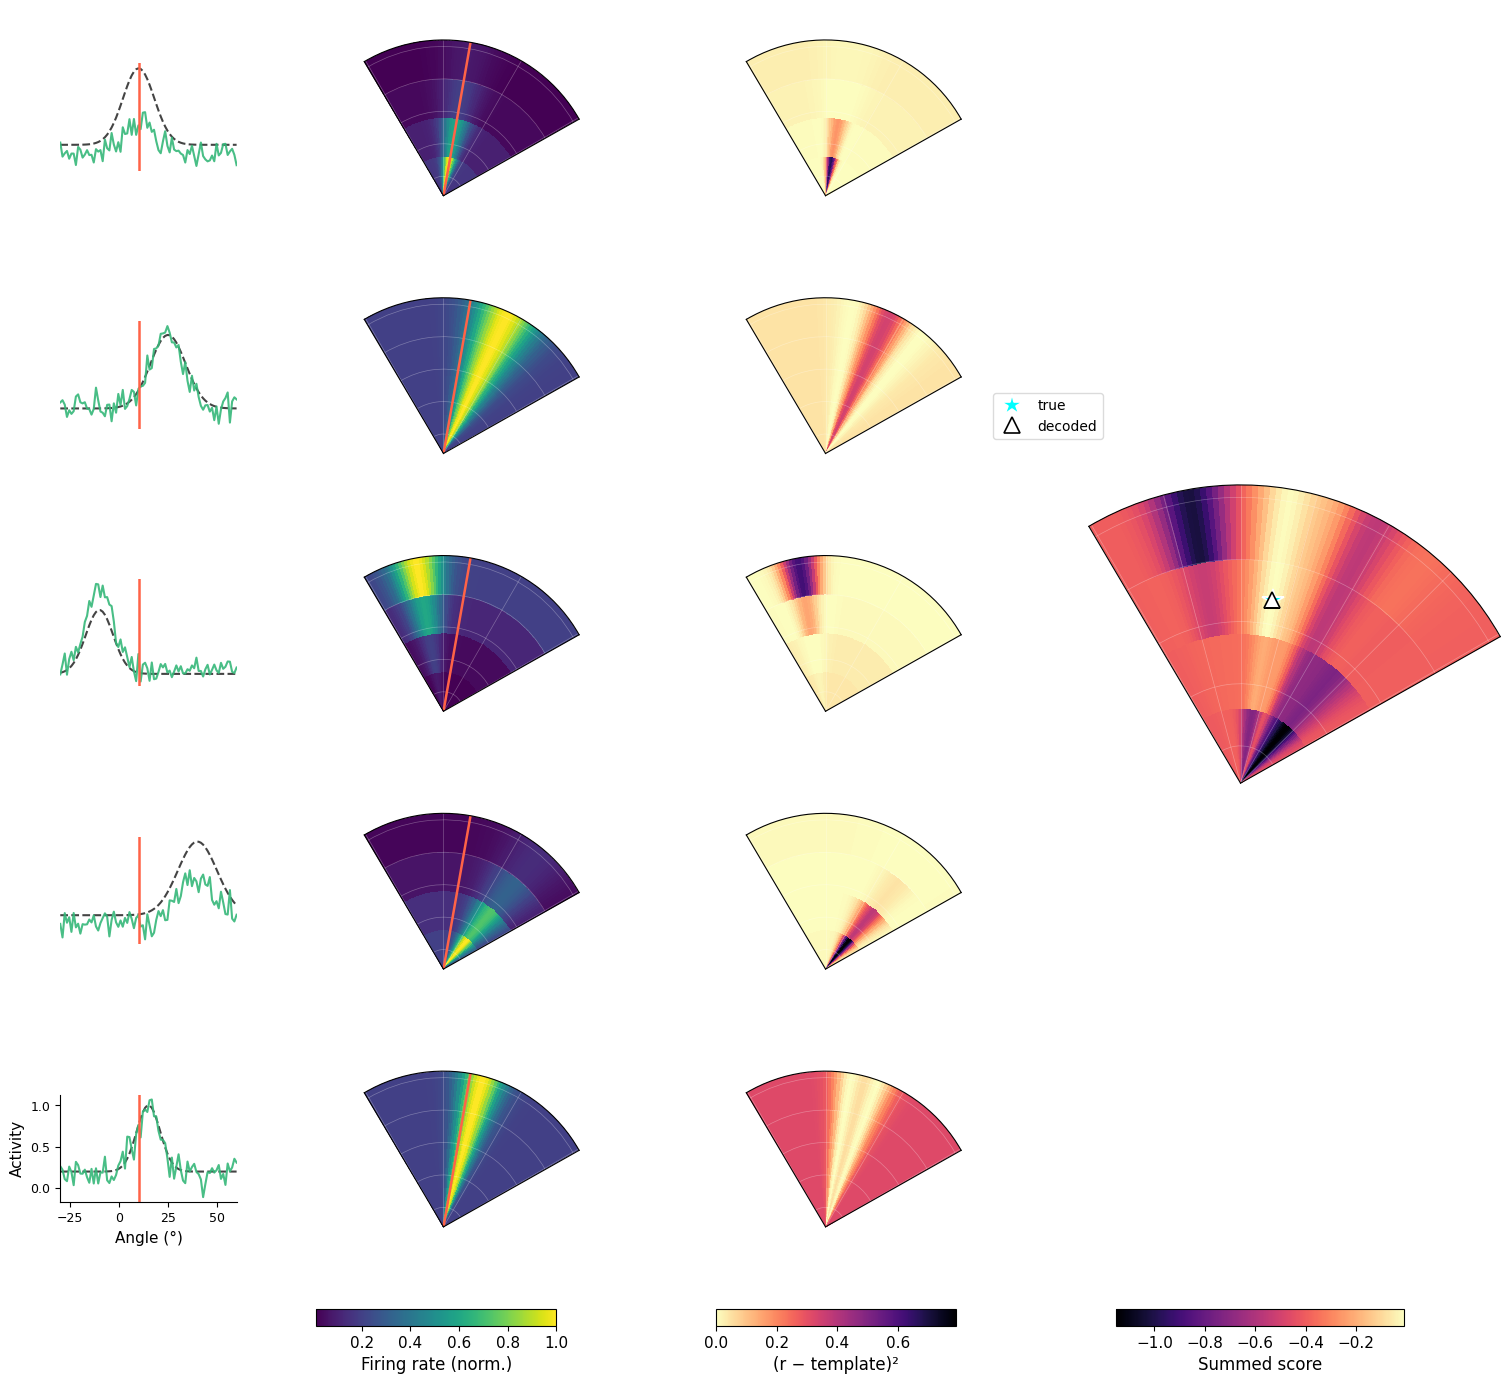

In [256]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

np.random.seed(7)
angle_axis    = np.linspace(-30, 60, 80)
distances     = np.array([10, 16, 22, 28])
noise_std     = 0.5
TRUE_DIST_IDX = 2
CHOSEN_ANGLE  = 10
chosen_idx    = np.argmin(np.abs(angle_axis - CHOSEN_ANGLE))

dist_colors = ['#440154', '#31688e', '#35b779', '#FFA500']
test_color  = dist_colors[TRUE_DIST_IDX]

def gauss(x, mu, sigma, amp):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + 1.0

cells = [
    dict(pref= 10, sigma=8,  amp=5.0, gain=[2.5, 1.5, 0.5, 0.2]),
    dict(pref= 25, sigma=9,  amp=4.0, gain=[1.0, 1.0, 1.0, 1.0]),
    dict(pref=-10, sigma=7,  amp=4.0, gain=[0.2, 0.5, 1.5, 2.5]),
    dict(pref= 40, sigma=10, amp=4.0, gain=[2.2, 1.6, 0.7, 0.3]),
    dict(pref= 15, sigma=6,  amp=4.0, gain=[1.0, 1.0, 1.0, 1.0]),
]

mu_avg, traces, templates = [], [], []
for p in cells:
    tuning = gauss(angle_axis, p['pref'], p['sigma'], p['amp'])
    avg    = np.mean([tuning * g for g in p['gain']], axis=0)
    trace  = tuning * p['gain'][TRUE_DIST_IDX] + np.random.randn(80) * noise_std
    tmpl   = np.outer(tuning, p['gain'])
    norm   = tmpl.max()
    mu_avg.append(avg   / norm)
    traces.append(trace / norm)
    templates.append(tmpl / norm)

sq_residuals = [(traces[c][chosen_idx] - templates[c]) ** 2 for c in range(5)]
tmpl_norm    = Normalize(vmin=min(t.min() for t in templates),
                          vmax=max(t.max() for t in templates))
resid_norm   = Normalize(vmin=0, vmax=max(s.max() for s in sq_residuals))

dtheta       = np.diff(angle_axis).mean()
theta_edges  = np.radians(np.append(angle_axis - dtheta/2, angle_axis[-1] + dtheta/2))
dr           = np.diff(distances).mean()
r_edges      = np.append(distances - dr/2, distances[-1] + dr/2)
chosen_theta = np.radians(CHOSEN_ANGLE)

fig = plt.figure(figsize=(16, 14))
gs  = gridspec.GridSpec(5, 4, figure=fig,
                        width_ratios=[0.6, 1, 1, 1.4],
                        hspace=0.2, wspace=0.3,
                        left=0.06, right=0.96, top=0.95, bottom=0.06)

def polar_ax(fig, spec):
    ax = fig.add_subplot(spec, projection='polar')
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ax.set_thetalim(theta_edges[0], theta_edges[-1])
    ax.set_rlim(r_edges[0], r_edges[-1])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.grid(color='white', linewidth=0.5, alpha=0.3)
    return ax

total_scores = np.zeros((len(angle_axis), len(distances)))
polar_tmpl   = []
polar_resid  = []

for c in range(5):
    ax_l = fig.add_subplot(gs[c, 0])
    ax_l.plot(angle_axis, mu_avg[c], '--', color='#444444', linewidth=1.5)
    ax_l.plot(angle_axis, traces[c],  '-', color=test_color, linewidth=1.5, alpha=0.9)
    ax_l.axvline(CHOSEN_ANGLE, color='tomato', linewidth=1.8)
    ax_l.set_xlim(angle_axis[0], angle_axis[-1])

    pos   = ax_l.get_position()
    shrink = 0.5
    new_h = pos.height * shrink
    ax_l.set_position([pos.x0, pos.y0 + (pos.height - new_h) / 2,
                       pos.width, new_h])

    if c < 4:
        ax_l.axis('off')
    else:
        ax_l.spines['top'].set_visible(False)
        ax_l.spines['right'].set_visible(False)
        ax_l.set_xlabel('Angle (°)', fontsize=11)
        ax_l.set_ylabel('Activity', fontsize=11)
        ax_l.tick_params(labelsize=9)

    ax_m = polar_ax(fig, gs[c, 1])
    ax_m.pcolormesh(theta_edges, r_edges, templates[c].T,
                    shading='flat', cmap='viridis', norm=tmpl_norm)
    ax_m.plot([chosen_theta, chosen_theta], [r_edges[0], r_edges[-1]],
              color='tomato', linewidth=1.8)
    polar_tmpl.append(ax_m)

    sq_resid      = sq_residuals[c]
    total_scores += -sq_resid

    ax_r = polar_ax(fig, gs[c, 2])
    ax_r.pcolormesh(theta_edges, r_edges, sq_resid.T,
                    shading='flat', cmap='magma_r', norm=resid_norm)
    polar_resid.append(ax_r)

total_norm = Normalize(vmin=total_scores.min(), vmax=total_scores.max())
ax_f = polar_ax(fig, gs[0:5, 3])
ax_f.pcolormesh(theta_edges, r_edges, total_scores.T,
                shading='flat', cmap='magma', norm=total_norm)

pred_a, pred_d = np.unravel_index(total_scores.argmax(), total_scores.shape)
ax_f.plot(chosen_theta,                   distances[TRUE_DIST_IDX], '*',
          color='cyan', markersize=16, markeredgecolor='white',
          markeredgewidth=1.2, zorder=5, label='true')
ax_f.plot(np.radians(angle_axis[pred_a]), distances[pred_d], '^',
          color='white', markersize=12, markeredgecolor='black',
          markeredgewidth=1.2, zorder=5, label='decoded')
ax_f.legend(loc='upper left', bbox_to_anchor=(-0.25, 1.1),
            fontsize=10, framealpha=0.7)

            # after plt loop — manual colorbar axes [left, bottom, width, height]
cax1 = fig.add_axes([0.22, 0.01, 0.15, 0.012])
cax2 = fig.add_axes([0.47, 0.01, 0.15, 0.012])
cax3 = fig.add_axes([0.72, 0.01, 0.18, 0.012])

fig.colorbar(ScalarMappable(norm=tmpl_norm,  cmap='viridis'),
             cax=cax1, orientation='horizontal', label='Firing rate (norm.)')
fig.colorbar(ScalarMappable(norm=resid_norm, cmap='magma_r'),
             cax=cax2, orientation='horizontal', label='(r − template)²')
fig.colorbar(ScalarMappable(norm=total_norm, cmap='magma'),
             cax=cax3, orientation='horizontal', label='Summed score')

plt.show()


# Averaged with same sampling

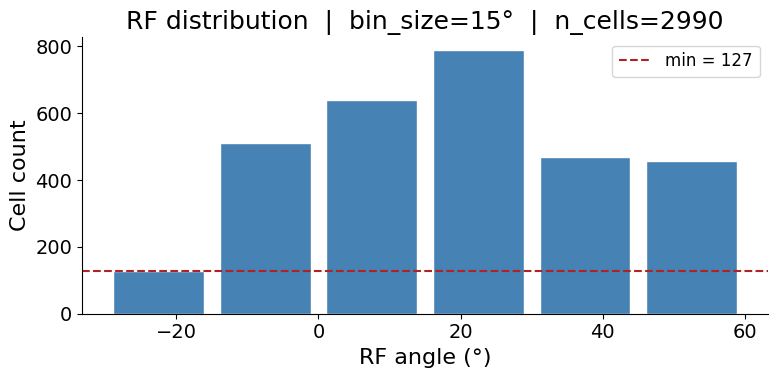

               Bin   Count
----------------------------
[-30.0°, -15.0°)     127
[-15.0°, +0.0°)     510
[+0.0°, +15.0°)     640
[+15.0°, +30.0°)     788
[+30.0°, +45.0°)     468
[+45.0°, +60.0°)     457
----------------------------
  Minimum (non-empty):     127


In [148]:
bin_edges, counts = agg.plot_rf_cell_distribution(bin_size=15, monocular=1)

In [180]:
mono_res = AveragedDecoder().cross_validate_balanced(
    agg, monocular=1, bin_size=15, n_per_bin=100,
    n_cell_repeats=10, n_repeats=10, random_state=42
)

bino_res = AveragedDecoder().cross_validate_balanced(
    agg, monocular=0, bin_size=15, n_per_bin=100,
    n_cell_repeats=10, n_repeats=10, random_state=42
)

Cell repeat 10/10
  Angle MAE:    7.72°
  Dist Acc:     29.6%
Cell repeat 10/10
  Angle MAE:    1.19°
  Dist Acc:     54.5%


In [173]:
print(np.size(bino_res['angle_mae_by_pos_all']))

590


In [5]:
decoder = AveragedDecoder()

bino_res_list = [decoder.cross_validate(a, monocular=0) for a in agg]
mono_res_list = [decoder.cross_validate(a, monocular=1) for a in agg]


Repeat 10/10
  Angle MAE:    0.79°
  Dist Acc:     41.9%
Repeat 10/10
  Angle MAE:    1.17°
  Dist Acc:     61.9%
Repeat 10/10
  Angle MAE:    0.92°
  Dist Acc:     52.1%
Repeat 10/10
  Angle MAE:    5.67°
  Dist Acc:     24.8%
Repeat 10/10
  Angle MAE:    11.11°
  Dist Acc:     31.8%
Repeat 10/10
  Angle MAE:    5.56°
  Dist Acc:     38.1%


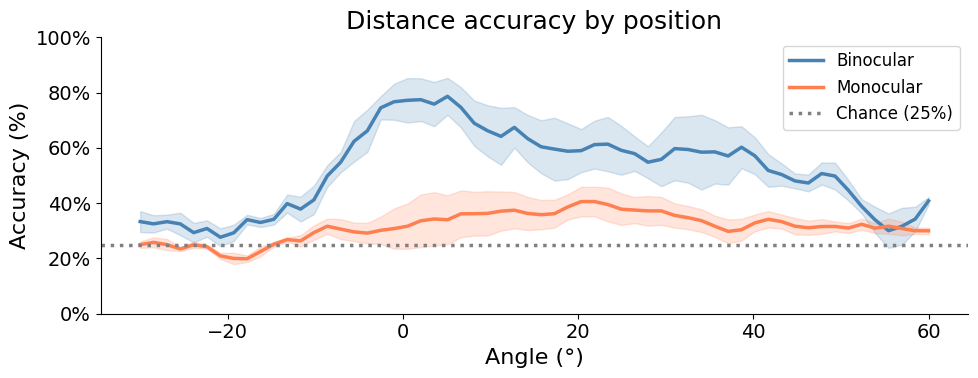

In [19]:
import os

fig = AveragedDecoder().plot_distance_results_multi(bino_res_list, mono_res_list)
figure_name = os.path.join(figure_dir, '6D.svg')
plt.rcParams['svg.fonttype'] = 'none'
fig.savefig(figure_name, format='svg')

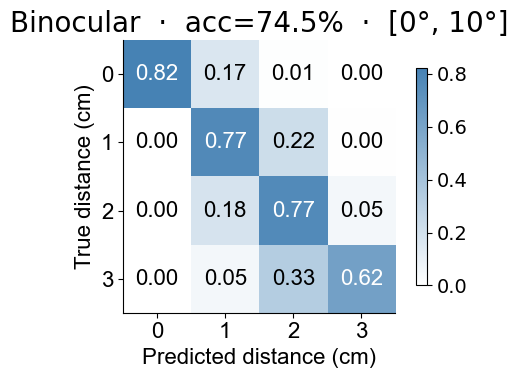

In [18]:
fig = AveragedDecoder().plot_confusion_central(bino_res_list)
figure_name = os.path.join(figure_dir, '6E.svg')
plt.rcParams['svg.fonttype'] = 'none'
fig.savefig(figure_name, format='svg')

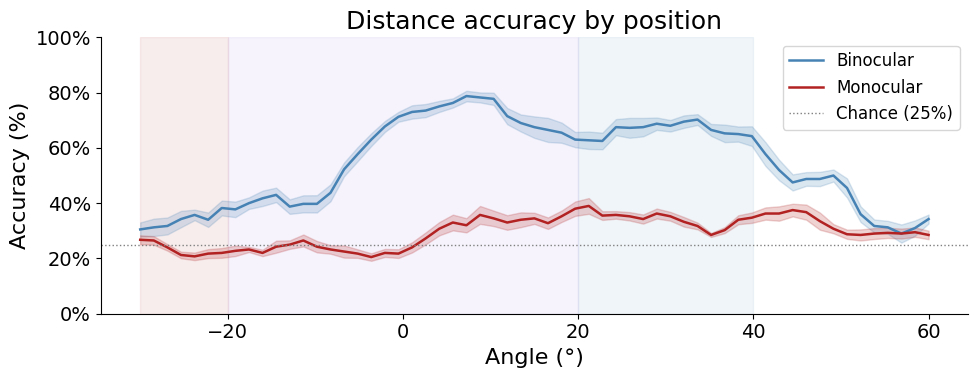

In [ ]:
fig = AveragedDecoder().plot_distance_results(bino_res, mono_res)

Repeat 10/10
  Angle MAE:    1.08°
  Dist Acc:     54.7%
Repeat 10/10
  Angle MAE:    2.59°
  Dist Acc:     32.3%


C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\decoding\Decoders.py:1464: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  


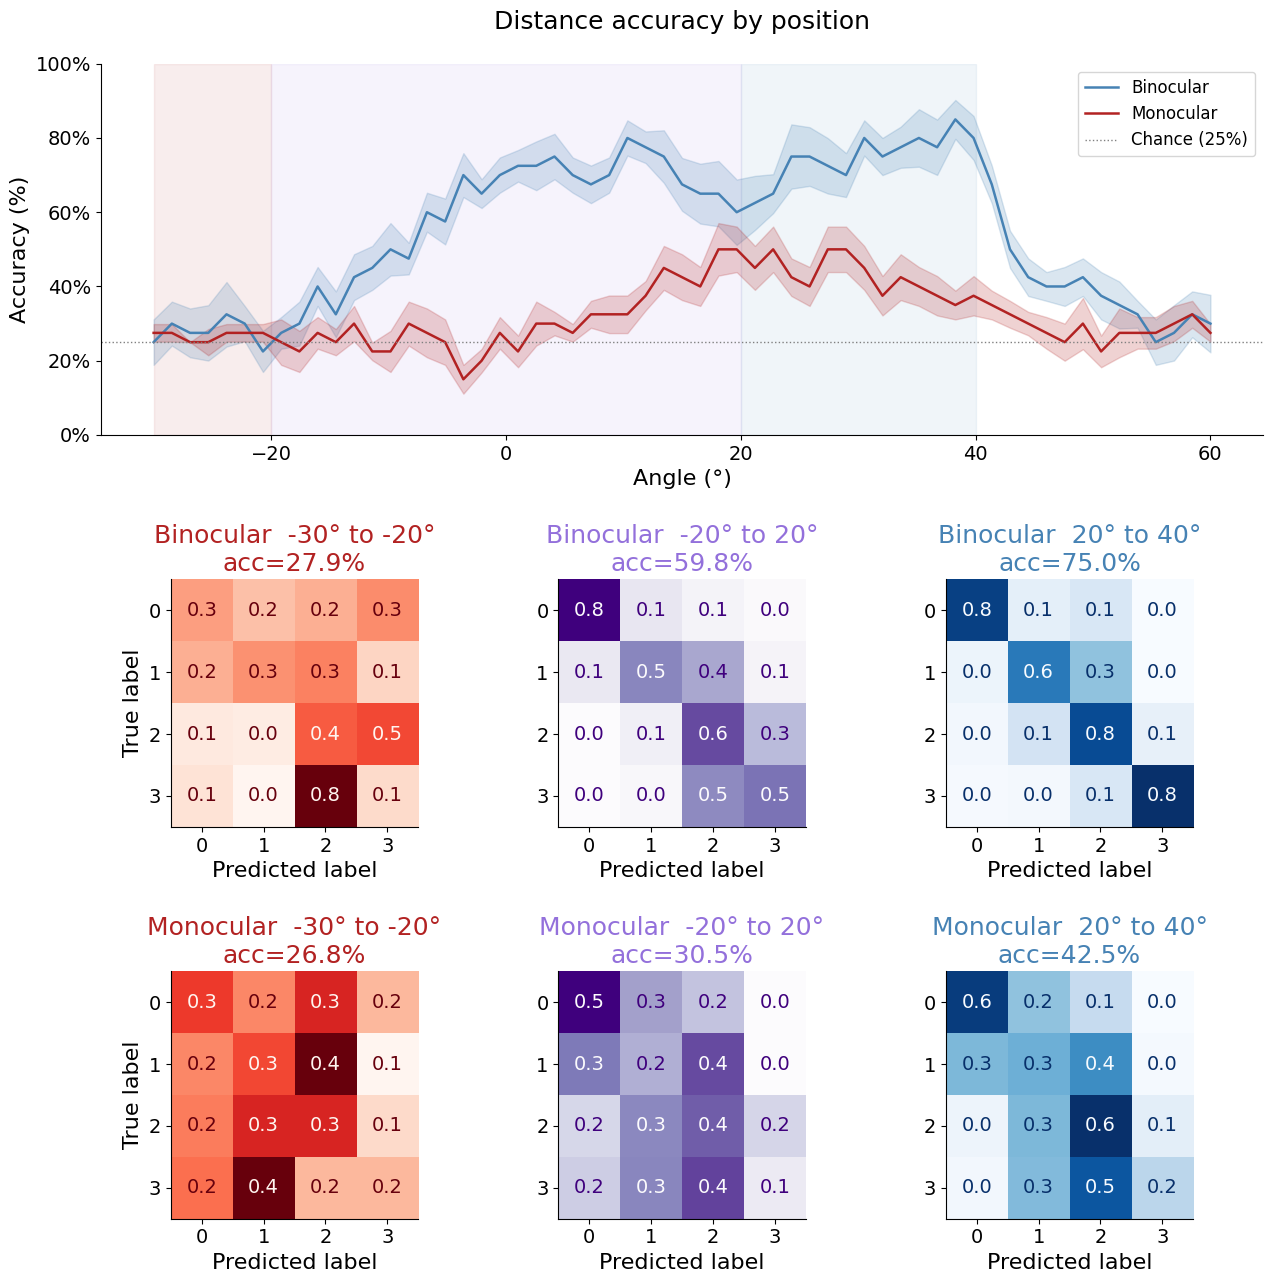

In [ ]:
cell_idx = agg.get_balanced_cell_idx(bin_size=10, monocular=0, random_state=42)

bino_res = AveragedDecoder().cross_validate(agg, monocular=0, n_repeats=10, cell_idx=cell_idx)
mono_res = AveragedDecoder().cross_validate(agg, monocular=1, n_repeats=10, cell_idx=cell_idx)

fig = AveragedDecoder().plot_distance_results(bino_res, mono_res)

In [189]:
bino_results_V1 = [AveragedDecoder().cross_validate(agg, monocular=0, area='V1', n_repeats=10) for agg in agg]
mono_results_V1  = [AveragedDecoder().cross_validate(agg, monocular=1, area='V1', n_repeats=10) for agg in agg]

bino_results_LM = [AveragedDecoder().cross_validate(agg, monocular=0, area='LM', n_repeats=10) for agg in agg]
mono_results_LM  = [AveragedDecoder().cross_validate(agg, monocular=1, area='LM', n_repeats=10) for agg in agg]

bino_results_RL = [AveragedDecoder().cross_validate(agg, monocular=0, area='RL', n_repeats=10) for agg in agg]
mono_results_RL  = [AveragedDecoder().cross_validate(agg, monocular=1, area='RL', n_repeats=10) for agg in agg]

Repeat 10/10
  Angle MAE:    0.61°
  Dist Acc:     37.8%
Repeat 10/10
  Angle MAE:    4.26°
  Dist Acc:     54.9%
Repeat 10/10
  Angle MAE:    0.86°
  Dist Acc:     64.8%
Repeat 10/10
  Angle MAE:    6.53°
  Dist Acc:     26.5%
Repeat 10/10
  Angle MAE:    1.46°
  Dist Acc:     38.6%
Repeat 10/10
  Angle MAE:    2.05°
  Dist Acc:     38.6%
Repeat 10/10
  Angle MAE:    2.72°
  Dist Acc:     30.5%
Repeat 10/10
  Angle MAE:    1.54°
  Dist Acc:     44.5%
Repeat 10/10
  Angle MAE:    2.13°
  Dist Acc:     34.6%
Repeat 10/10
  Angle MAE:    21.25°
  Dist Acc:     26.8%
Repeat 10/10
  Angle MAE:    11.77°
  Dist Acc:     25.4%
Repeat 10/10
  Angle MAE:    2.95°
  Dist Acc:     26.3%
Repeat 10/10
  Angle MAE:    3.52°
  Dist Acc:     32.2%
Repeat 10/10
  Angle MAE:    2.18°
  Dist Acc:     41.3%
Repeat 10/10
  Angle MAE:    8.29°
  Dist Acc:     28.4%
Repeat 10/10
  Angle MAE:    11.79°
  Dist Acc:     24.5%
Repeat 10/10
  Angle MAE:    8.78°
  Dist Acc:     23.9%
Repeat 10/10
  Angle MAE:   

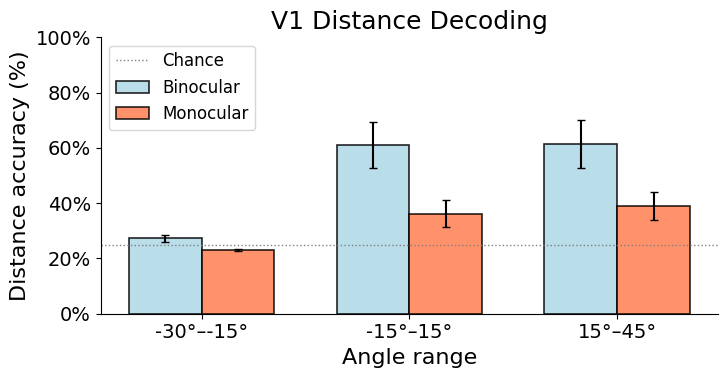

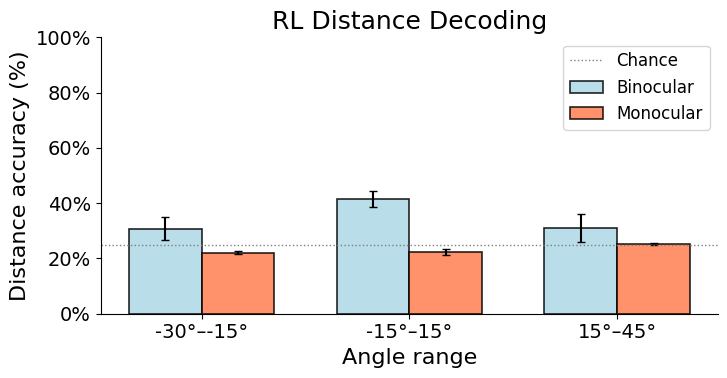

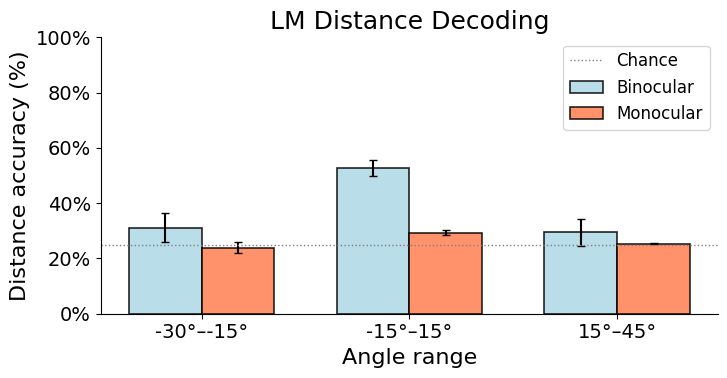

In [191]:
fig, ax = AveragedDecoder().plot_mice_range_comparison(
    bino_results_V1, mono_results_V1,
    angle_ranges=[(-30, -15), (-15, 15), (15, 45)],
    title='V1 Distance Decoding'
)

fig, ax = AveragedDecoder().plot_mice_range_comparison(
    bino_results_RL, mono_results_RL,
    angle_ranges=[(-30, -15), (-15, 15), (15, 45)],
    title='RL Distance Decoding'
)

fig, ax = AveragedDecoder().plot_mice_range_comparison(
    bino_results_LM, mono_results_LM,
    angle_ranges=[(-30, -15), (-15, 15), (15, 45)],
    title='LM Distance Decoding'
)

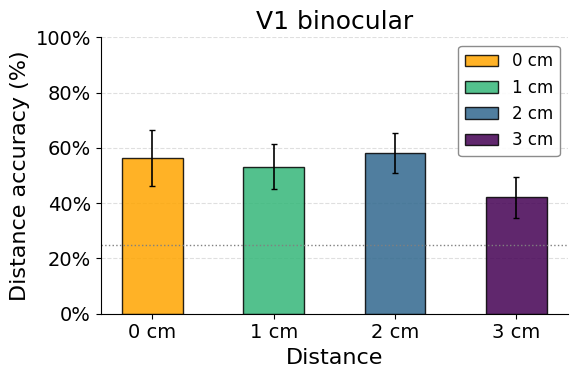

In [196]:
fig, ax = AveragedDecoder().plot_accuracy_by_distance(bino_results_V1, title='V1 binocular')
